# House Price Prediction

## 1. Problem Statement

**Task 1:** Prepare a complete data analysis report on the given data.

**Task 2:**
- a) Create a robust machine learning model to accurately predict the price of a house given the various factors across the market.
- b) Determine the relationship between the house features and how the price varies based on them.

**Task 3:** Come up with suggestions for a customer to buy a house according to area, price and other requirements.

## 2. Business Objective

Buying a house is one of the biggest financial decisions a customer makes, and it is hard to know whether an asking price is fair. A house price depends on many things at once: size, quality, age, neighborhood, garage, basement and more. In this project we use machine learning to estimate the price of a house from its features, understand which features matter most, and use this to guide customers towards a good purchase.

## 3. Dataset Description

The dataset contains 1,460 house sales with 80 features and the target `SalePrice` (in US dollars). The main columns are:

**Location / Lot**
- `MSZoning`: General zoning classification of the sale
- `Neighborhood`: Physical location within the city (the "area")
- `LotArea`, `LotFrontage`: Lot size in square feet and street frontage
- `LotShape`, `LandContour`, `LotConfig`, `Street`, `Alley`: Lot shape and access details

**House Type and Style**
- `MSSubClass`, `BldgType`, `HouseStyle`: Type of dwelling and style (1 story, 2 story, etc.)
- `YearBuilt`, `YearRemodAdd`: Original construction year and remodel year
- `RoofStyle`, `Exterior1st`, `Foundation`: Roof, exterior and foundation details

**Quality and Condition**
- `OverallQual`, `OverallCond`: Overall material/finish quality and condition (1-10)
- `ExterQual`, `KitchenQual`, `HeatingQC`, `BsmtQual`: Quality of exterior, kitchen, heating and basement (Ex, Gd, TA, Fa, Po)

**Size and Rooms**
- `GrLivArea`, `1stFlrSF`, `2ndFlrSF`, `TotalBsmtSF`: Above-ground living area, floor areas and basement area (sq ft)
- `BedroomAbvGr`, `KitchenAbvGr`, `TotRmsAbvGrd`: Bedrooms, kitchens and total rooms above ground
- `FullBath`, `HalfBath`, `BsmtFullBath`, `BsmtHalfBath`: Number of bathrooms

**Extras**
- `GarageType`, `GarageCars`, `GarageArea`: Garage details
- `Fireplaces`, `FireplaceQu`: Number and quality of fireplaces
- `WoodDeckSF`, `OpenPorchSF`, `EnclosedPorch`, `ScreenPorch`: Deck and porch areas
- `PoolArea`, `PoolQC`, `Fence`, `CentralAir`: Pool, fence and air conditioning

**Sale Information**
- `MoSold`, `YrSold`, `SaleType`, `SaleCondition`: When and how the house was sold
- `SalePrice`: **Target variable**, the price the house was sold for

## 4. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 5. Data Loading

In [2]:
data = pd.read_csv('data.csv')

## 6. Initial Data Exploration

In [3]:
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
data.shape

(1460, 81)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [6]:
data.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [7]:
data.select_dtypes(exclude='number').describe()

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
count,1460,1460,91,1460,1460,1460,1460,1460,1460,1460,...,1379,1379,1379,1379,1460,7,281,54,1460,1460
unique,5,2,2,4,4,2,5,3,25,9,...,6,3,5,5,3,3,4,4,9,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,1151,1454,50,925,1311,1459,1052,1382,225,1260,...,870,605,1311,1326,1340,3,157,49,1267,1198


## 7. Data Cleaning

In [8]:
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

pd.DataFrame({'Missing': missing, 'Percent': (missing / len(data) * 100).round(1)})

,Missing,Percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


In [9]:
data.duplicated().sum()

np.int64(0)

Most missing values are not real "missing data". In columns such as `Alley`, `PoolQC`, `Fence`, `FireplaceQu`, and the basement and garage columns, a blank means the house **does not have** that feature (no pool, no garage, etc.). These are filled with `'None'`. The remaining gaps are filled as follows:
- `LotFrontage`: median of the same neighborhood
- `MasVnrArea`: 0 (no masonry veneer)
- `Electrical`: most common value (only 1 missing)
- `GarageYrBlt`: dropped, because it is almost the same as `YearBuilt`
- `Id`: dropped, because it is only a row number

In [10]:
none_cols = ['Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1',
             'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
             'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']

for col in none_cols:
    data[col] = data[col].fillna('None')

In [11]:
data['LotFrontage'] = data.groupby('Neighborhood')['LotFrontage'].transform(lambda x: x.fillna(x.median()))
data['LotFrontage'] = data['LotFrontage'].fillna(data['LotFrontage'].median())

data['MasVnrArea'] = data['MasVnrArea'].fillna(0)
data['Electrical'] = data['Electrical'].fillna(data['Electrical'].mode()[0])

data = data.drop(['Id', 'GarageYrBlt'], axis=1)

Next we check for outliers. Two very large houses (above 4,000 sq ft living area) were sold at unusually low prices, which looks like unusual sales rather than normal market behaviour.

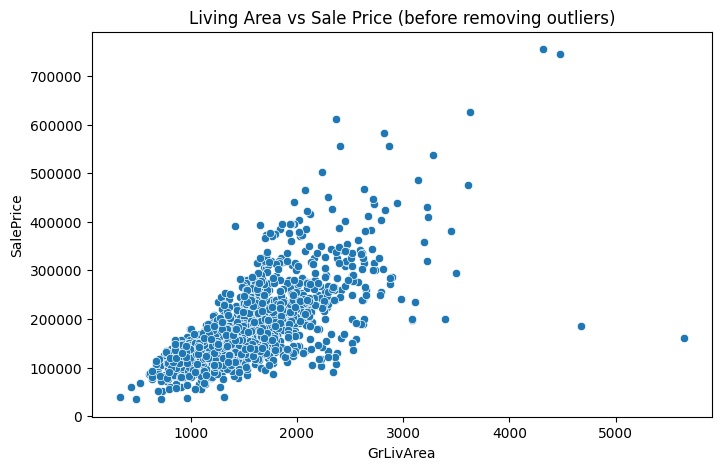

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='GrLivArea', y='SalePrice')
plt.title('Living Area vs Sale Price (before removing outliers)')
plt.show()

In [13]:
outliers = data[(data['GrLivArea'] > 4000) & (data['SalePrice'] < 300000)]
outliers[['Neighborhood', 'GrLivArea', 'OverallQual', 'SaleCondition', 'SalePrice']]

,Neighborhood,GrLivArea,OverallQual,SaleCondition,SalePrice
523,Edwards,4676,10,Partial,184750
1298,Edwards,5642,10,Partial,160000


In [14]:
data = data.drop(outliers.index)

In [15]:
print(data.shape)
print(data.isnull().sum().sum())
print(data.duplicated().sum())

(1458, 79)
0
0


## 8. Exploratory Data Analysis (Task 1: Data Analysis Report)

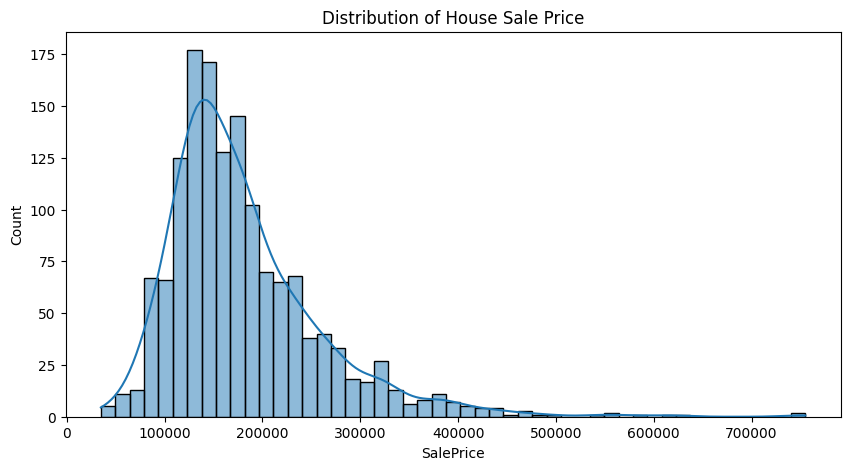

Skewness: 1.88


In [16]:
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='SalePrice', kde=True)
plt.title('Distribution of House Sale Price')
plt.show()

print('Skewness:', round(data['SalePrice'].skew(), 2))

In [17]:
data['SalePrice'].describe()

count      1458.000000
mean     180932.919067
std       79495.055285
min       34900.000000
25%      129925.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

**Observation:** House prices are right-skewed (skewness about 1.9). Half of the houses sold between roughly $130,000 and $214,000, the median price is $163,000 and the average ($180,933) is pulled up by a small number of expensive houses, with the maximum at $755,000. Only 28 houses sold for more than $400,000.

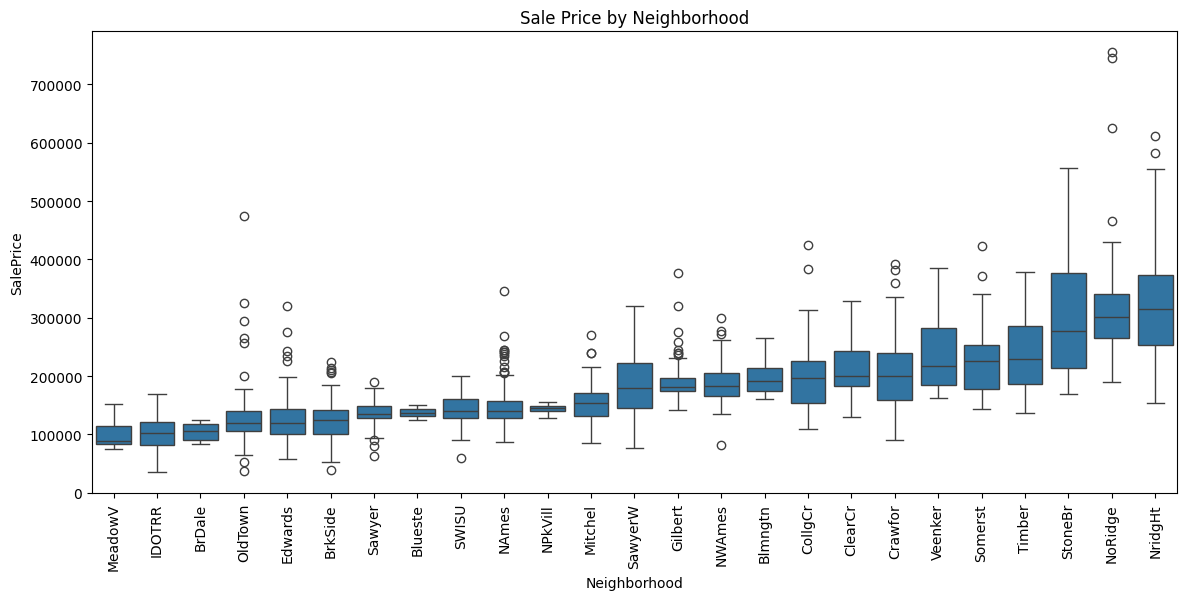

In [18]:
order = data.groupby('Neighborhood')['SalePrice'].median().sort_values().index

plt.figure(figsize=(14, 6))
sns.boxplot(data=data, x='Neighborhood', y='SalePrice', order=order)
plt.xticks(rotation=90)
plt.title('Sale Price by Neighborhood')
plt.show()

**Observation:** Neighborhood has a very strong effect on price. The median price ranges from $88,000 in MeadowV to $315,000 in NridgHt. NridgHt, NoRidge and StoneBr are the most expensive areas (median $278,000 and above), while MeadowV, IDOTRR, BrDale, OldTown and Edwards are the most affordable (median around $120,000 or less).

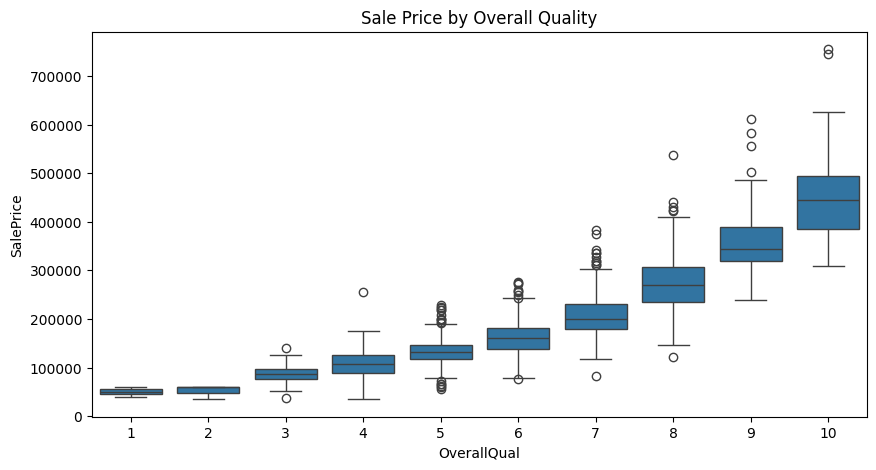

In [19]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=data, x='OverallQual', y='SalePrice')
plt.title('Sale Price by Overall Quality')
plt.show()

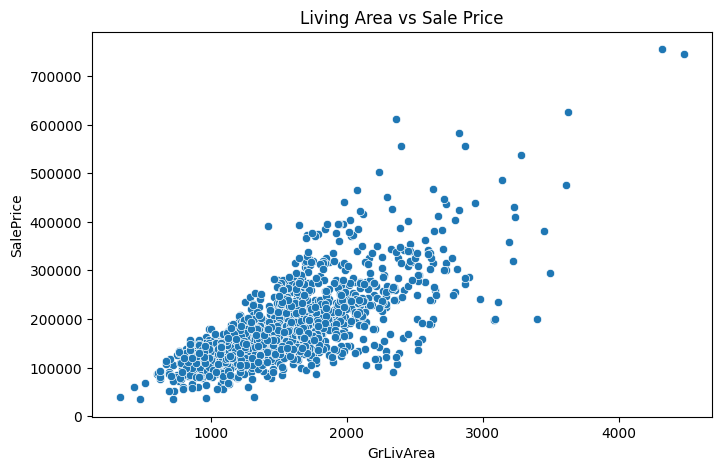

In [20]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='GrLivArea', y='SalePrice')
plt.title('Living Area vs Sale Price')
plt.show()

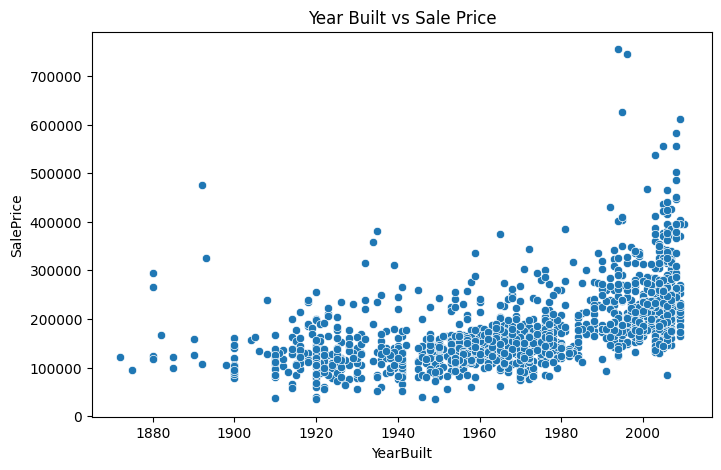

In [21]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x='YearBuilt', y='SalePrice')
plt.title('Year Built vs Sale Price')
plt.show()

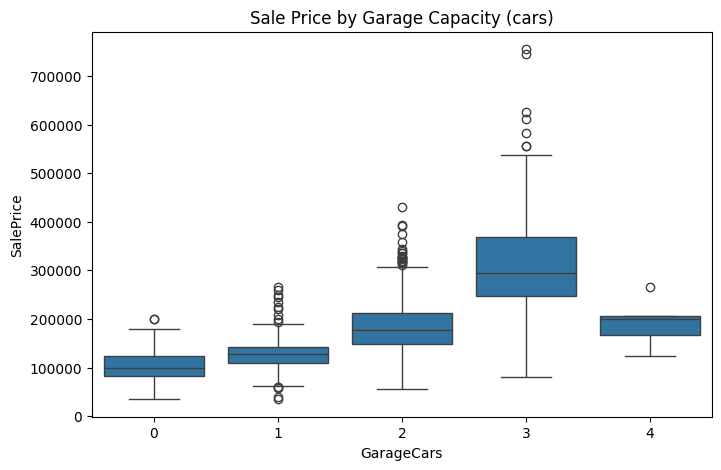

In [22]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='GarageCars', y='SalePrice')
plt.title('Sale Price by Garage Capacity (cars)')
plt.show()

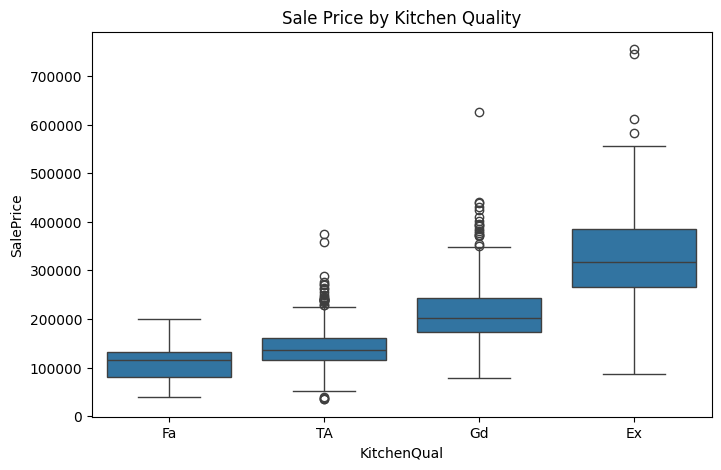

In [23]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=data, x='KitchenQual', y='SalePrice', order=['Fa', 'TA', 'Gd', 'Ex'])
plt.title('Sale Price by Kitchen Quality')
plt.show()

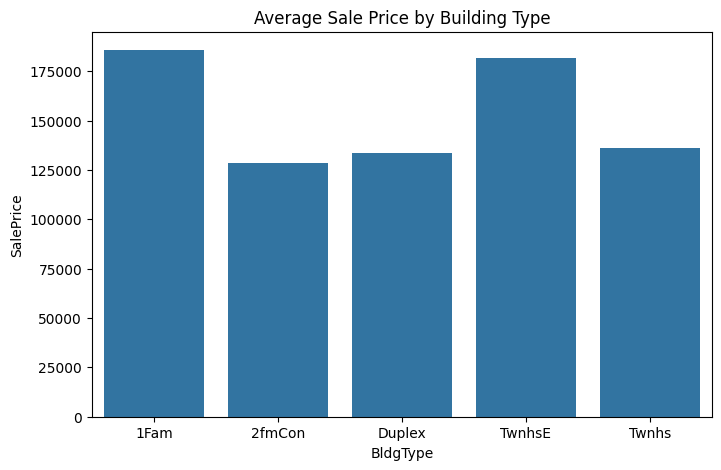

In [24]:
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='BldgType', y='SalePrice', errorbar=None)
plt.title('Average Sale Price by Building Type')
plt.show()

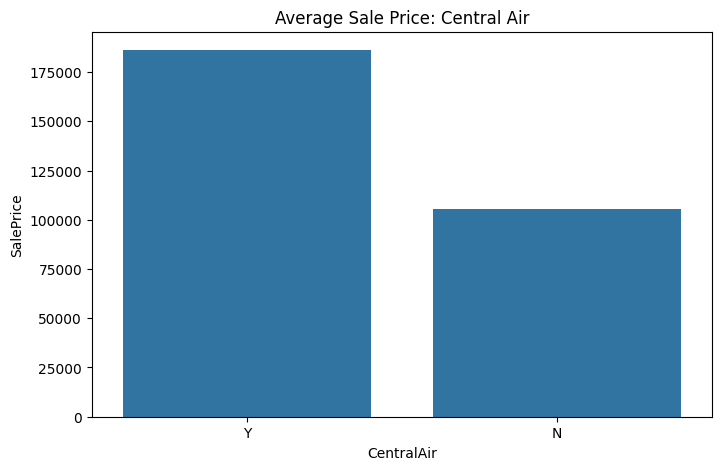

In [25]:
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='CentralAir', y='SalePrice', errorbar=None)
plt.title('Average Sale Price: Central Air')
plt.show()

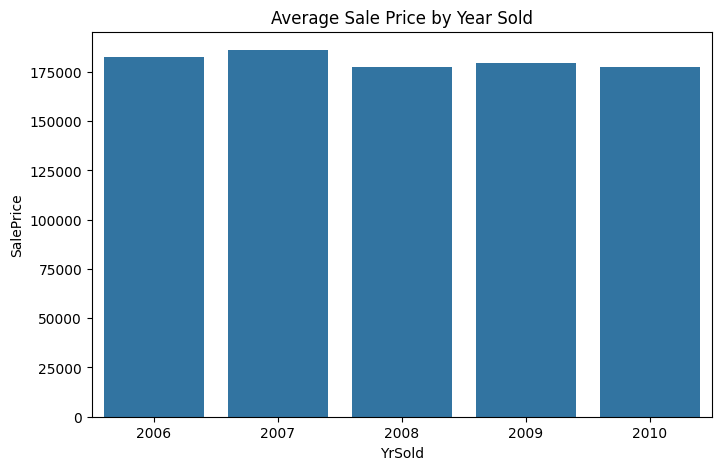

In [26]:
plt.figure(figsize=(8, 5))
sns.barplot(data=data, x='YrSold', y='SalePrice', errorbar=None)
plt.title('Average Sale Price by Year Sold')
plt.show()

### Correlation with Sale Price

In [27]:
corr = data.corr(numeric_only=True)['SalePrice'].drop('SalePrice').sort_values(ascending=False)
corr.head(10)

OverallQual     0.795774
GrLivArea       0.734968
TotalBsmtSF     0.651153
GarageCars      0.641047
1stFlrSF        0.631530
GarageArea      0.629217
FullBath        0.562165
TotRmsAbvGrd    0.537769
YearBuilt       0.523608
YearRemodAdd    0.507717
Name: SalePrice, dtype: float64

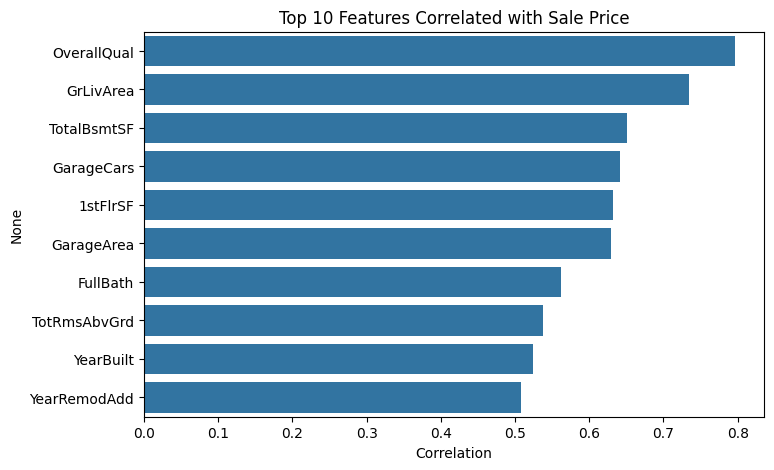

In [28]:
plt.figure(figsize=(8, 5))
sns.barplot(x=corr.head(10).values, y=corr.head(10).index)
plt.title('Top 10 Features Correlated with Sale Price')
plt.xlabel('Correlation')
plt.show()

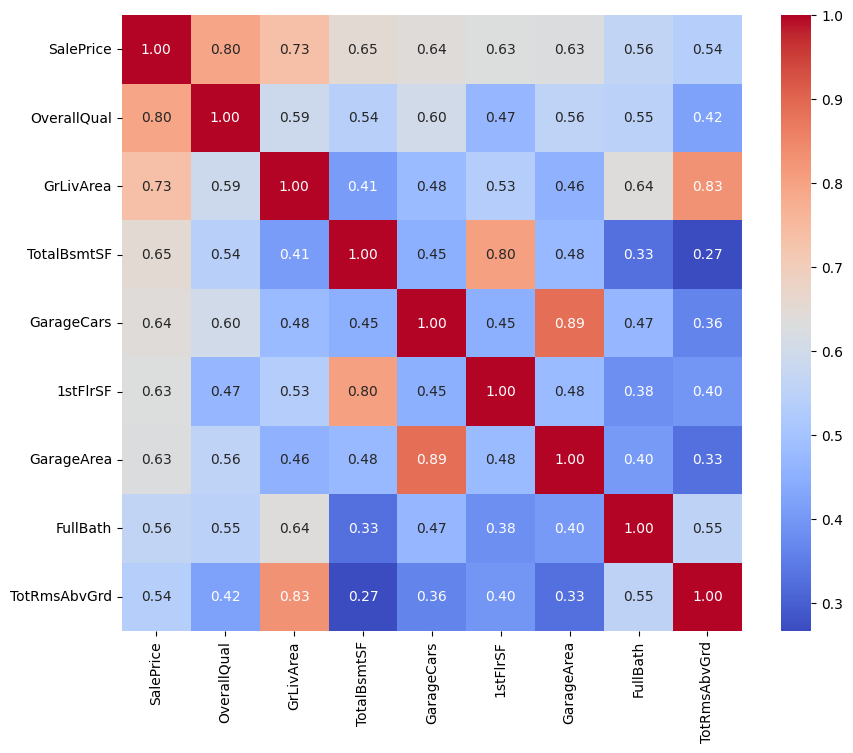

In [29]:
top_cols = ['SalePrice'] + list(corr.head(8).index)

plt.figure(figsize=(10, 8))
sns.heatmap(data[top_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.show()

### Key Findings from the Data Analysis

- **Quality and size drive price.** `OverallQual` (0.80) and `GrLivArea` (0.73) have the strongest correlation with `SalePrice`, followed by basement area, garage capacity and first-floor area.
- **Each quality step adds a lot.** The median price is about $133,000 at quality 5, $200,000 at quality 7, $270,000 at quality 8 and $445,000 at quality 10.
- **Newer houses cost more.** Median price is about $122,000 for houses built before 1950, $143,000 for 1951-1980, $197,000 for 1981-2000 and $225,000 for houses built after 2000.
- **Garage and kitchen matter.** Median price rises from $100,000 (no garage) to $178,000 (2-car garage), and from $137,000 (typical kitchen) to $201,000 (good) and $318,000 (excellent kitchen). Houses with central air have a median of $168,000 versus $98,000 without it.
- **Building type.** Single-family houses (1Fam) and end-unit townhouses (TwnhsE) average about $182,000-$186,000, while duplexes, 2-family conversions and inner townhouses average $128,000-$136,000.
- **The market was flat during 2006-2010.** Average price stayed between about $177,000 and $186,000 in each year, so the sale year has little influence on the price.
- **Many size-related columns are correlated with each other** (for example `GarageCars` and `GarageArea`, or `1stFlrSF` and `TotalBsmtSF`), so the models can use any of them to capture size.

## 9. Feature Engineering

New features that describe a house better are created from existing columns, and the quality columns (Excellent, Good, Typical...) are converted to numbers so the models can use their order. Remaining text columns are one-hot encoded.

In [30]:
data['TotalSF'] = data['TotalBsmtSF'] + data['1stFlrSF'] + data['2ndFlrSF']
data['HouseAge'] = (data['YrSold'] - data['YearBuilt']).clip(lower=0)
data['RemodAge'] = (data['YrSold'] - data['YearRemodAdd']).clip(lower=0)
data['TotalBathrooms'] = (data['FullBath'] + 0.5 * data['HalfBath']
                          + data['BsmtFullBath'] + 0.5 * data['BsmtHalfBath'])
data['TotalPorchSF'] = (data['OpenPorchSF'] + data['EnclosedPorch']
                        + data['3SsnPorch'] + data['ScreenPorch'])

data[['TotalSF', 'HouseAge', 'RemodAge', 'TotalBathrooms', 'TotalPorchSF']].head()

,TotalSF,HouseAge,RemodAge,TotalBathrooms,TotalPorchSF
0,2566,5,5,3.5,61
1,2524,31,31,2.5,0
2,2706,7,6,3.5,42
3,2473,91,36,2.0,307
4,3343,8,8,3.5,84


In [31]:
quality_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

quality_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond', 'PoolQC']

for col in quality_cols:
    data[col] = data[col].map(quality_map)

data[quality_cols].isnull().sum().sum()

np.int64(0)

In [32]:
# MSSubClass is a code for dwelling type, not a real number, so treat it as a category
data['MSSubClass'] = data['MSSubClass'].astype(str)

Before encoding, a small table with the main house details is saved. It is used later in Task 3 (buying suggestions).

In [33]:
house_info = data[['Neighborhood', 'SalePrice', 'GrLivArea', 'OverallQual', 'BedroomAbvGr',
                   'TotalBathrooms', 'GarageCars', 'HouseAge', 'TotalSF', 'SaleCondition']].copy()
house_info['Price_per_SF'] = house_info['SalePrice'] / house_info['GrLivArea']

house_info.head()

,Neighborhood,SalePrice,GrLivArea,OverallQual,BedroomAbvGr,TotalBathrooms,GarageCars,HouseAge,TotalSF,SaleCondition,Price_per_SF
0,CollgCr,208500,1710,7,3,3.5,2,5,2566,Normal,121.929825
1,Veenker,181500,1262,6,3,2.5,2,31,2524,Normal,143.819334
2,CollgCr,223500,1786,7,3,3.5,2,7,2706,Normal,125.139978
3,Crawfor,140000,1717,7,3,2.0,3,91,2473,Abnorml,81.537566
4,NoRidge,250000,2198,8,4,3.5,3,8,3343,Normal,113.739763


In [34]:
cat_cols = data.select_dtypes(exclude='number').columns
print('Number of categorical columns:', len(cat_cols))

data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=int)

Number of categorical columns: 34


In [35]:
print('Final Shape of Data:', data.shape)

Final Shape of Data: (1458, 246)


## Feature Engineering Summary

- Missing values that meant "no feature" were filled with `None`, and other gaps with median / mode / 0.
- `TotalSF`, `HouseAge`, `RemodAge`, `TotalBathrooms` and `TotalPorchSF` were created.
- Quality ratings were converted into a 0-5 scale.
- Remaining categorical columns (Neighborhood, house style, etc.) were one-hot encoded.

## 10. Train-Test Split

In [36]:
X = data.drop('SalePrice', axis=1)
y = data['SalePrice']

In [37]:
print(X.shape)
print(y.shape)

(1458, 245)
(1458,)


In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [39]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1166, 245)
(292, 245)
(1166,)
(292,)


## Model Evaluation

The models are evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

- MAE measures the average absolute difference between actual and predicted prices (in dollars).
- RMSE gives greater weight to larger prediction errors.
- R² indicates how much variation in house prices is explained by the model.

## 11. Baseline Model

In [40]:
from sklearn.linear_model import LinearRegression

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
y_pred_lr = model_lr.predict(X_test)

In [42]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("MAE:", mae_lr)
print("RMSE:", rmse_lr)
print("R² Score:", r2_lr)

MAE: 20355.140496261258
RMSE: 28393.015125502392
R² Score: 0.8540544716260657


In [43]:
from sklearn.ensemble import RandomForestRegressor

model_rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [44]:
y_pred_rf = model_rf.predict(X_test)

In [45]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("MAE:", mae_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

MAE: 16584.02636986301
RMSE: 24760.3324479594
R² Score: 0.8890108031853128


In [46]:
from sklearn.ensemble import GradientBoostingRegressor

model_gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model_gb.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [47]:
y_pred_gb = model_gb.predict(X_test)

In [48]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("MAE:", mae_gb)
print("RMSE:", rmse_gb)
print("R² Score:", r2_gb)

MAE: 14905.218154541903
RMSE: 20934.65105784668
R² Score: 0.9206587171167354


Checking the training score of Random Forest to see whether the model is overfitting.

In [49]:
y_train_pred_rf = model_rf.predict(X_train)

mae_train_rf = mean_absolute_error(y_train, y_train_pred_rf)
rmse_train_rf = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
r2_train_rf = r2_score(y_train, y_train_pred_rf)

print("Training MAE:", mae_train_rf)
print("Training RMSE:", rmse_train_rf)
print("Training R²:", r2_train_rf)

Training MAE: 6302.71205831904
Training RMSE: 10124.50789088079
Training R²: 0.9842620032446998


### Hyperparameter Tuning (GridSearchCV)

In [50]:
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, None],
    'max_features': [0.3, 0.5]
}

In [51]:
from sklearn.model_selection import GridSearchCV

rf_grid = RandomForestRegressor(random_state=42, n_jobs=-1)

grid_search_rf = GridSearchCV(
    estimator=rf_grid,
    param_grid=param_grid_rf,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid_search_rf.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, None], 'max_features': [0.3, 0.5], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [52]:
print(grid_search_rf.best_params_)
print(grid_search_rf.best_score_)

{'max_depth': None, 'max_features': 0.3, 'n_estimators': 200}
0.8927668441744342


In [53]:
best_rf = grid_search_rf.best_estimator_

y_pred_rf_best = best_rf.predict(X_test)

mae_rf_best = mean_absolute_error(y_test, y_pred_rf_best)
rmse_rf_best = np.sqrt(mean_squared_error(y_test, y_pred_rf_best))
r2_rf_best = r2_score(y_test, y_pred_rf_best)

print("MAE:", mae_rf_best)
print("RMSE:", rmse_rf_best)
print("R² Score:", r2_rf_best)

MAE: 15718.849332191783
RMSE: 22200.330659477724
R² Score: 0.9107749804777062


In [54]:
param_grid_gb = {
    'n_estimators': [200, 300],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4]
}

In [55]:
gb_grid = GradientBoostingRegressor(random_state=42)

grid_search_gb = GridSearchCV(
    estimator=gb_grid,
    param_grid=param_grid_gb,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid_search_gb.fit(X_train, y_train)

,estimator,GradientBoost...ndom_state=42)
,param_grid,"{'learning_rate': [0.05, 0.1], 'max_depth': [3, 4], 'n_estimators': [200, 300]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'squared_error'


In [56]:
print(grid_search_gb.best_params_)
print(grid_search_gb.best_score_)

{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300}
0.9074042810638175


In [57]:
best_gb = grid_search_gb.best_estimator_

y_pred_gb_best = best_gb.predict(X_test)

mae_gb_best = mean_absolute_error(y_test, y_pred_gb_best)
rmse_gb_best = np.sqrt(mean_squared_error(y_test, y_pred_gb_best))
r2_gb_best = r2_score(y_test, y_pred_gb_best)

print("MAE:", mae_gb_best)
print("RMSE:", rmse_gb_best)
print("R² Score:", r2_gb_best)

MAE: 14262.323295806857
RMSE: 20230.73087318644
R² Score: 0.9259046572890672


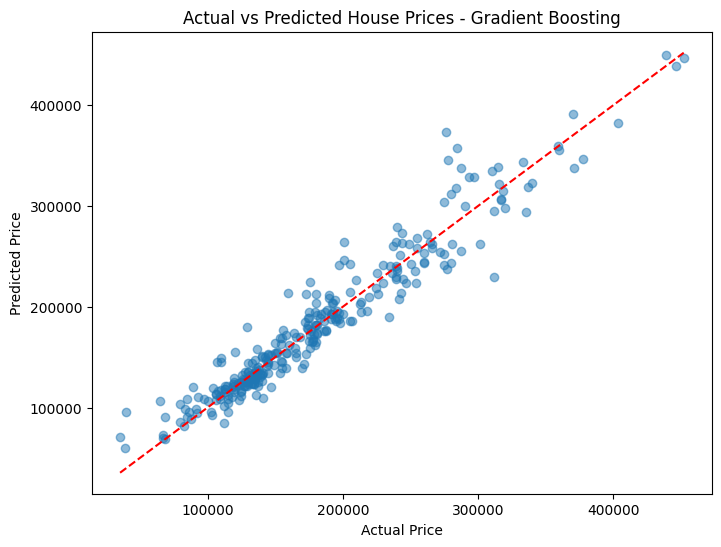

In [58]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_gb_best, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')

plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Prices - Gradient Boosting')

plt.show()

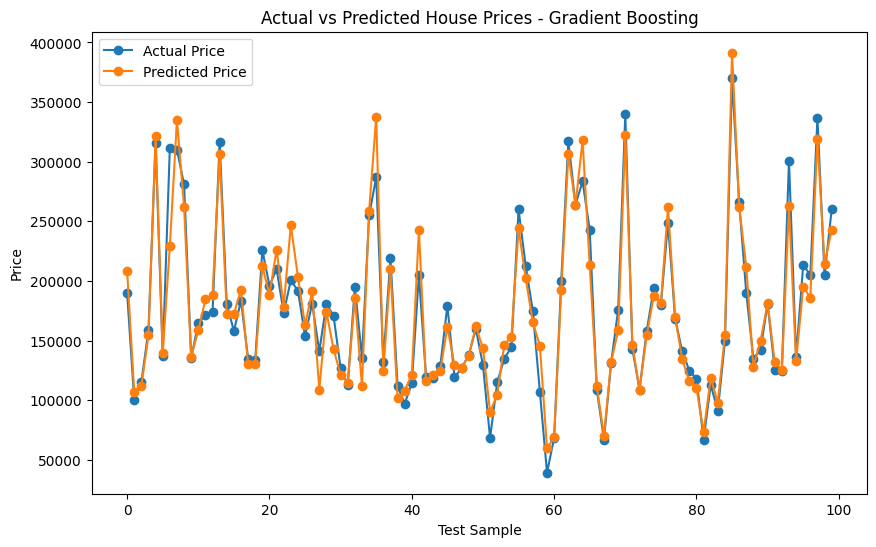

In [59]:
plt.figure(figsize=(10, 6))

plt.plot(y_test.values[:100], marker='o', label='Actual Price')
plt.plot(y_pred_gb_best[:100], marker='o', label='Predicted Price')

plt.xlabel('Test Sample')
plt.ylabel('Price')
plt.title('Actual vs Predicted House Prices - Gradient Boosting')
plt.legend()

plt.show()

## 12. Error Analysis

The tuned Gradient Boosting model has the lowest MAE and RMSE and the highest R² on the test set, so it is selected as the final model for the rest of the analysis.

In [60]:
final_model = best_gb

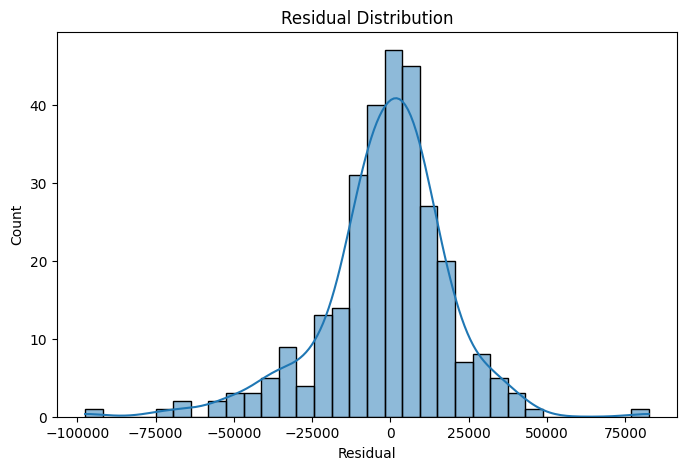

In [61]:
y_pred_final = final_model.predict(X_test)
residuals = y_test - y_pred_final

plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual")
plt.title("Residual Distribution")
plt.show()

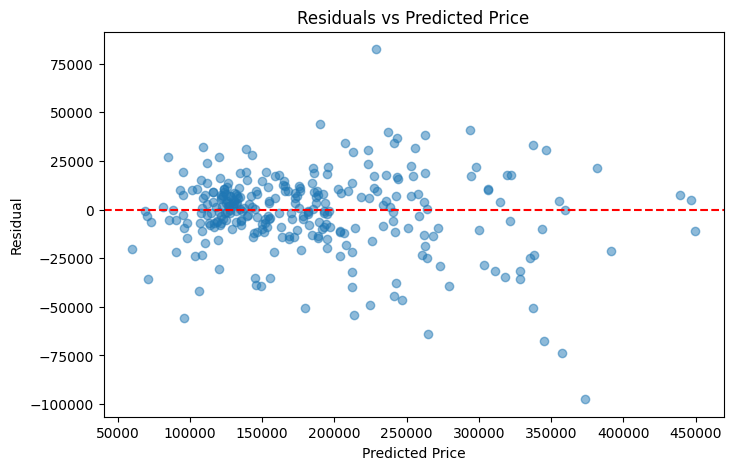

In [62]:
plt.figure(figsize=(8, 5))
plt.scatter(y_pred_final, residuals, alpha=0.5)
plt.axhline(0, linestyle='--', color='red')
plt.xlabel("Predicted Price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted Price")
plt.show()

In [63]:
error_pct = (residuals.abs() / y_test * 100)

print("Average error (% of price):", round(error_pct.mean(), 1))
print("Median error (% of price):", round(error_pct.median(), 1))
print("Houses predicted within 10% of the actual price:", round((error_pct <= 10).mean() * 100, 1), "%")

Average error (% of price): 8.9
Median error (% of price): 5.9
Houses predicted within 10% of the actual price: 76.0 %


In [64]:
error_by_band = pd.DataFrame({'Error_%': error_pct})
error_by_band['Price Band'] = pd.cut(y_test, [0, 130000, 200000, 300000, 800000],
                                     labels=['Under $130k', '$130k-$200k', '$200k-$300k', 'Over $300k'])

error_by_band.groupby('Price Band', observed=True)['Error_%'].agg(['count', 'mean']).round(1)

,count,mean
Price Band,,
Under $130k,78,13.5
$130k-$200k,125,6.6
$200k-$300k,66,9.0
Over $300k,23,6.0


**Error Analysis Observation:** The residuals are centered around zero, so the model is not biased towards over- or under-pricing. On average the prediction is off by about 8.9% of the price (median 5.9%), and 76% of test houses are predicted within 10% of the actual price. Errors are larger for cheaper houses (about 13% for houses under $130,000) because a few thousand dollars is a bigger share of a small price, and a few large errors remain for unusual houses. Cross-validation gives R² of about 0.92 and MAE of about $14,900, close to the test-set result, so the model is stable.

### Cross-Validation Check

To make sure the result does not depend on one lucky train-test split, the final model is checked with 5-fold cross-validation. Every house gets a prediction from a model that never saw it. These predictions are also reused in Task 3.

In [65]:
from sklearn.model_selection import cross_val_predict

cv_pred = cross_val_predict(final_model, X, y, cv=5)

print("Cross-validated MAE:", mean_absolute_error(y, cv_pred))
print("Cross-validated RMSE:", np.sqrt(mean_squared_error(y, cv_pred)))
print("Cross-validated R² Score:", r2_score(y, cv_pred))

Cross-validated MAE: 14875.460496828791
Cross-validated RMSE: 22526.355826425253
Cross-validated R² Score: 0.919647457960379


## 13. Model Comparison

Five regression models were evaluated: Linear Regression, Random Forest, Gradient Boosting, GridSearch Random Forest and GridSearch Gradient Boosting. Hyperparameter tuning (GridSearchCV, 3-fold) was applied to Random Forest and Gradient Boosting, and the tuned models were evaluated on the same test set. The untuned Random Forest overfits (training R² 0.98 vs test R² 0.89), and tuning reduced this gap. The tuned Gradient Boosting model has the best MAE, RMSE and R² (MAE $14,244, RMSE $20,204, R² 0.926) and is selected as the final model.

In [66]:
model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting',
        'GridSearch Random Forest',
        'GridSearch Gradient Boosting'
    ],
    'MAE': [mae_lr, mae_rf, mae_gb, mae_rf_best, mae_gb_best],
    'RMSE': [rmse_lr, rmse_rf, rmse_gb, rmse_rf_best, rmse_gb_best],
    'R2 Score': [r2_lr, r2_rf, r2_gb, r2_rf_best, r2_gb_best]
})

model_comparison.round(3)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20355.140,28393.015,0.854
1,Random Forest,16584.026,24760.332,0.889
2,Gradient Boosting,14905.218,20934.651,0.921
3,GridSearch Random Forest,15718.849,22200.331,0.911
4,GridSearch Gradient Boosting,14262.323,20230.731,0.926


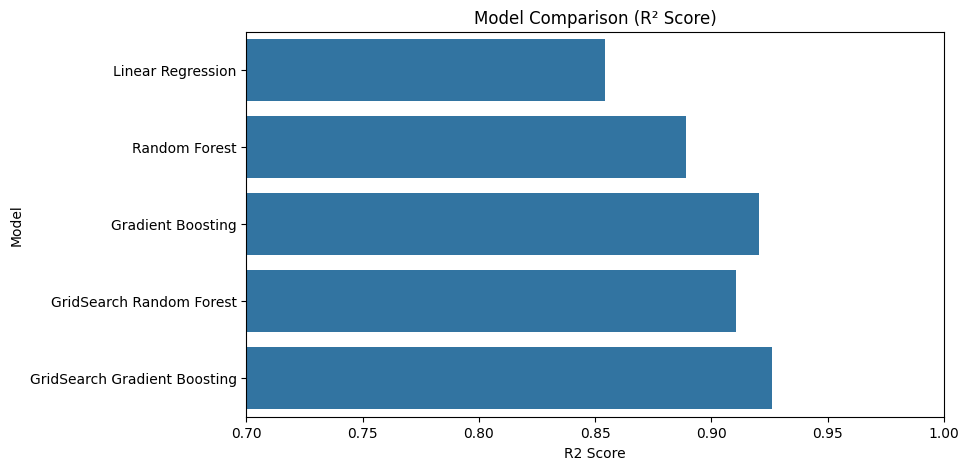

In [67]:
plt.figure(figsize=(9, 5))
sns.barplot(data=model_comparison, x='R2 Score', y='Model')
plt.title('Model Comparison (R² Score)')
plt.xlim(0.7, 1.0)
plt.show()

## 14. Feature Importance and Price Relationships (Task 2b)

### Which features matter most?

In [68]:
importance = pd.Series(final_model.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(15)

TotalSF           0.426683
OverallQual       0.297347
TotalBathrooms    0.030909
HouseAge          0.025734
GarageCars        0.024371
GrLivArea         0.020363
BsmtQual          0.020035
KitchenQual       0.019359
BsmtFinSF1        0.017994
LotArea           0.013051
2ndFlrSF          0.008804
GarageArea        0.008011
YearBuilt         0.007133
YearRemodAdd      0.006914
FireplaceQu       0.006900
dtype: float64

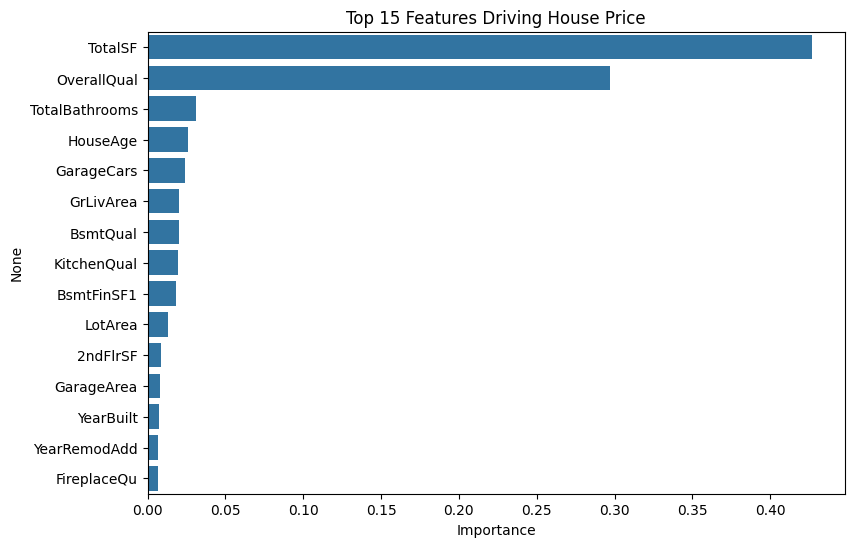

In [69]:
plt.figure(figsize=(9, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index)
plt.title('Top 15 Features Driving House Price')
plt.xlabel('Importance')
plt.show()

**Observation:** Two features dominate: `TotalSF` (total living plus basement area, about 43% of importance) and `OverallQual` (overall quality, about 30%). Together they explain roughly 72% of the model's decisions. Next come bathrooms, house age, garage capacity, basement and kitchen quality, and lot area. Neighborhood matters too, but its effect is spread across many separate neighborhood columns.

### How does the price change when a feature changes?

To see how much each feature adds to the price, we increase one feature at a time for **every house in the test data**, let the model predict the new prices, and take the average change. Using all houses gives a more stable answer than using a single house.

In [70]:
base_pred = final_model.predict(X_test)
print("Average predicted price of test houses:", round(base_pred.mean()))

Average predicted price of test houses: 183008


In [71]:
changes = {
    'Overall quality +1 point': ('OverallQual', 1),
    'Total area +500 sq ft': ('TotalSF', 500),
    'Garage capacity +1 car': ('GarageCars', 1),
    'One more bathroom': ('TotalBathrooms', 1),
    'Kitchen quality +1 level': ('KitchenQual', 1),
    'One more fireplace': ('Fireplaces', 1),
    'House 10 years older': ('HouseAge', 10)
}

rows = []
for name, (col, change) in changes.items():
    X_new = X_test.copy()
    # keep the new value inside the range seen in the data (e.g. quality cannot go above 10)
    X_new[col] = (X_new[col] + change).clip(lower=X[col].min(), upper=X[col].max())
    avg_change = (final_model.predict(X_new) - base_pred).mean()
    rows.append({'Change': name,
                 'Avg Price Change ($)': round(avg_change),
                 'Avg Price Change (%)': round(avg_change / base_pred.mean() * 100, 1)})

what_if = pd.DataFrame(rows).sort_values('Avg Price Change ($)', ascending=False)
what_if

,Change,Avg Price Change ($),Avg Price Change (%)
1,Total area +500 sq ft,18566,10.1
0,Overall quality +1 point,9760,5.3
3,One more bathroom,7118,3.9
4,Kitchen quality +1 level,4756,2.6
2,Garage capacity +1 car,3620,2.0
5,One more fireplace,618,0.3
6,House 10 years older,-852,-0.5


**Observation:** Adding area has the biggest effect: +500 sq ft raises the predicted price by about $18,600 (10%). One more quality point adds about $9,800 (5%), one more bathroom about $7,100 (4%), a better kitchen about $4,800 (2.6%) and one more garage space about $3,600 (2%). The age of the house on its own has almost no effect once size and quality are held fixed, which suggests newer houses cost more mainly because they tend to be bigger and better finished. These are model estimates of association, not guaranteed returns from renovations.

### Neighborhood effect

Location matters even for houses of similar size. The table compares neighborhoods using price per square foot of living area.

In [72]:
area_price = house_info.groupby('Neighborhood').agg(
    Houses=('SalePrice', 'count'),
    Median_Price=('SalePrice', 'median'),
    Median_Price_per_SF=('Price_per_SF', 'median')
).round(1).sort_values('Median_Price_per_SF', ascending=False)

area_price.head(5)

,Houses,Median_Price,Median_Price_per_SF
Neighborhood,,,
NridgHt,77,315000.0,158.0
StoneBr,25,278000.0,157.9
Veenker,11,218000.0,143.8
Somerst,86,225500.0,137.4
Blmngtn,17,191000.0,137.1


In [73]:
area_price.tail(5)

,Houses,Median_Price,Median_Price_per_SF
Neighborhood,,,
MeadowV,17,88000.0,92.1
OldTown,113,119000.0,92.1
BrDale,16,106000.0,91.1
IDOTRR,37,103000.0,90.6
SWISU,25,139500.0,80.6


## 15. Buying Suggestions for the Customer (Task 3)

The suggestions are built in three steps:
1. Group neighborhoods into Budget, Mid-range and Premium areas.
2. Use the model to check whether a house is priced fairly. If the model's predicted price is higher than the sale price, the house is a good deal.
3. Filter houses by the customer's budget and requirements and show the best deals first.

### Step 1: Area-wise price summary

Foreclosures, family transfers and other unusual sales are left out, because their prices do not reflect what a normal buyer would pay. Neighborhoods with fewer than 10 sales are also left out because the numbers would not be reliable.

In [74]:
house_info['Predicted_Price'] = cv_pred
house_info['Value_Gap'] = house_info['Predicted_Price'] - house_info['SalePrice']
house_info['Value_%'] = house_info['Value_Gap'] / house_info['Predicted_Price'] * 100

# Foreclosures, family sales, allocation and adjoining-land sales are not normal market deals,
# so only Normal and Partial (new construction) sales are used for the suggestions
market_sales = house_info[house_info['SaleCondition'].isin(['Normal', 'Partial'])].copy()
print('Houses used for suggestions:', len(market_sales), 'of', len(house_info))

area_summary = market_sales.groupby('Neighborhood').agg(
    Houses=('SalePrice', 'count'),
    Median_Price=('SalePrice', 'median'),
    Avg_Quality=('OverallQual', 'mean'),
    Median_Size_SF=('GrLivArea', 'median'),
    Median_Price_per_SF=('Price_per_SF', 'median'),
    Avg_Value_Pct=('Value_%', 'mean')
)

# Only neighborhoods with enough sales are used so that the numbers are reliable
area_summary = area_summary[area_summary['Houses'] >= 10].copy()

area_summary['Tier'] = pd.qcut(area_summary['Median_Price'], 3, labels=['Budget', 'Mid-range', 'Premium'])
area_summary = area_summary.sort_values('Median_Price').round(1)

area_summary

Houses used for suggestions: 1321 of 1458


,Houses,Median_Price,Avg_Quality,Median_Size_SF,Median_Price_per_SF,Avg_Value_Pct,Tier
Neighborhood,,,,,,,
MeadowV,16,87000.0,4.4,1092.0,90.1,7.3,Budget
BrDale,12,109500.0,5.7,1102.5,92.3,-0.2,Budget
IDOTRR,29,110000.0,5.0,1192.0,91.9,1.8,Budget
OldTown,96,121000.0,5.5,1384.5,94.0,1.4,Budget
Edwards,84,121750.0,5.0,1217.0,99.6,1.9,Budget
BrkSide,54,127000.0,5.1,1210.5,101.3,-3.3,Budget
Sawyer,67,135000.0,5.0,1068.0,122.1,0.4,Budget
SWISU,22,138475.0,5.5,1669.0,81.2,2.8,Budget
NAmes,198,142000.0,5.4,1207.0,120.9,-0.1,Mid-range


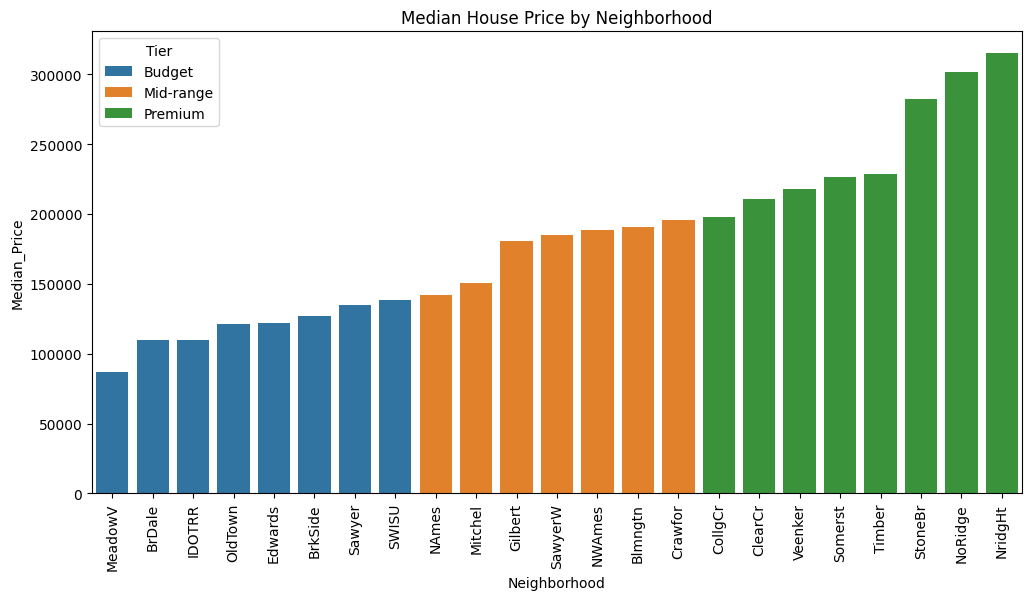

In [75]:
plt.figure(figsize=(12, 6))
sns.barplot(data=area_summary.reset_index(), x='Neighborhood', y='Median_Price', hue='Tier', dodge=False)
plt.xticks(rotation=90)
plt.title('Median House Price by Neighborhood')
plt.show()

In [76]:
for tier in ['Budget', 'Mid-range', 'Premium']:
    group = area_summary[area_summary['Tier'] == tier]
    print(tier, '| price range: $', int(group['Median_Price'].min()), '-', int(group['Median_Price'].max()))
    print('   ', ', '.join(group.index))

Budget | price range: $ 87000 - 138475
    MeadowV, BrDale, IDOTRR, OldTown, Edwards, BrkSide, Sawyer, SWISU
Mid-range | price range: $ 142000 - 195550
    NAmes, Mitchel, Gilbert, SawyerW, NWAmes, Blmngtn, Crawfor
Premium | price range: $ 197900 - 315000
    CollgCr, ClearCr, Veenker, Somerst, Timber, StoneBr, NoRidge, NridgHt


**Observation:** Budget areas have median prices up to about $138,000 (MeadowV, BrDale, IDOTRR, OldTown, Edwards, BrkSide, Sawyer, SWISU). Mid-range areas run from about $142,000 to $196,000 (NAmes, Mitchel, Gilbert, SawyerW, NWAmes, Blmngtn, Crawfor). Premium areas start at about $198,000 and go up to $315,000 (CollgCr, ClearCr, Veenker, Somerst, Timber, StoneBr, NoRidge, NridgHt). NridgHt and StoneBr are the most expensive per square foot (about $158), while SWISU is the cheapest (about $81).

### Step 2: Which areas give the best value?

`Avg_Value_Pct` shows how much cheaper (positive) or more expensive (negative) houses in an area are compared to what the model expects for their features.

In [77]:
area_summary[['Houses', 'Median_Price', 'Avg_Quality', 'Avg_Value_Pct']].sort_values('Avg_Value_Pct', ascending=False)

,Houses,Median_Price,Avg_Quality,Avg_Value_Pct
Neighborhood,,,,
MeadowV,16,87000.0,4.4,7.3
SWISU,22,138475.0,5.5,2.8
Edwards,84,121750.0,5.0,1.9
IDOTRR,29,110000.0,5.0,1.8
OldTown,96,121000.0,5.5,1.4
Mitchel,43,150900.0,5.5,0.4
SawyerW,51,184900.0,6.4,0.4
Sawyer,67,135000.0,5.0,0.4
CollgCr,147,197900.0,6.6,0.3


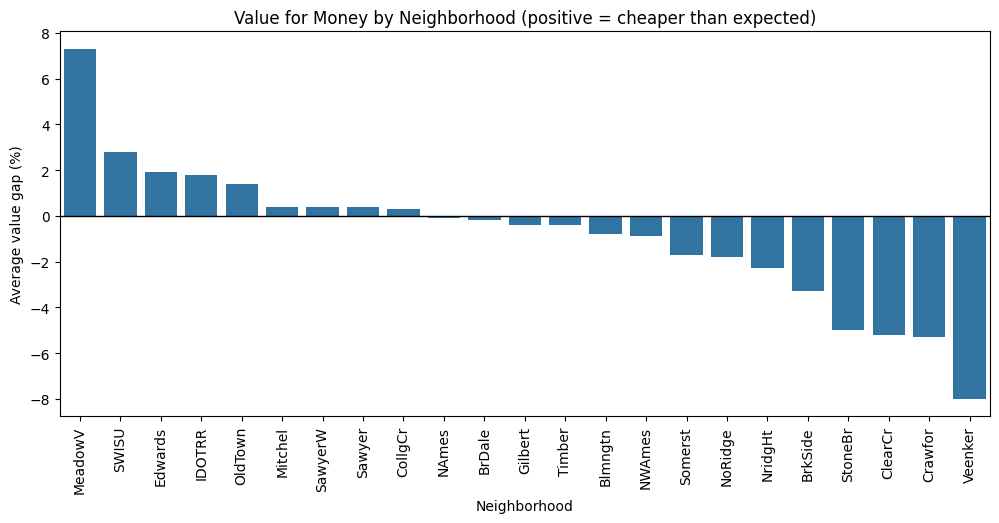

In [78]:
plt.figure(figsize=(12, 5))
value_sorted = area_summary['Avg_Value_Pct'].sort_values(ascending=False)
sns.barplot(x=value_sorted.index, y=value_sorted.values)
plt.axhline(0, color='black', linewidth=1)
plt.xticks(rotation=90)
plt.ylabel('Average value gap (%)')
plt.title('Value for Money by Neighborhood (positive = cheaper than expected)')
plt.show()

**Observation:** Most neighborhoods are priced close to what their features justify (within about 2%). Houses in MeadowV, SWISU, IDOTRR, Edwards and OldTown tend to sell slightly below the model's expected price, so they offer the best value for money, though MeadowV and SWISU have few sales and lower quality. Crawfor, ClearCr, StoneBr and Veenker tend to sell above the model's expected price, so buyers pay a location premium there. Veenker has only 11 sales, so treat its result with caution.

### Step 3: House recommendation function

The function takes the customer's budget and requirements and returns the best-value houses (largest gap between predicted price and actual price).

Houses that look more than 30% cheaper than the model expects are left out (`max_gap_pct`). The model is usually within about 10% of the real price, so a gap this large is more likely a hidden problem or an unusual sale than a real bargain, and such houses should be inspected carefully rather than recommended.

In [79]:
def recommend_houses(budget, min_bedrooms=1, min_bathrooms=1, min_garage=0,
                     min_quality=1, neighborhoods=None, top_n=5, max_gap_pct=30):

    result = market_sales[
        (market_sales['SalePrice'] <= budget) &
        (market_sales['BedroomAbvGr'] >= min_bedrooms) &
        (market_sales['TotalBathrooms'] >= min_bathrooms) &
        (market_sales['GarageCars'] >= min_garage) &
        (market_sales['OverallQual'] >= min_quality) &
        (market_sales['Value_%'] <= max_gap_pct)
    ]

    if neighborhoods is not None:
        result = result[result['Neighborhood'].isin(neighborhoods)]

    result = result.sort_values('Value_%', ascending=False).head(top_n)

    return result[['Neighborhood', 'SalePrice', 'Predicted_Price', 'Value_Gap', 'Value_%', 'GrLivArea',
                   'BedroomAbvGr', 'TotalBathrooms', 'GarageCars', 'OverallQual', 'HouseAge']].round(1)

**Customer 1:** Small family, budget up to $150,000, needs 3 bedrooms, a garage and at least average quality.

In [80]:
recommend_houses(budget=150000, min_bedrooms=3, min_garage=1, min_quality=5)

,Neighborhood,SalePrice,Predicted_Price,Value_Gap,Value_%,GrLivArea,BedroomAbvGr,TotalBathrooms,GarageCars,OverallQual,HouseAge
560,Sawyer,121500,167736.0,46236.0,27.6,1392,3,2.5,2,5,53
1383,Sawyer,112000,152378.7,40378.7,26.5,1416,3,2.0,2,5,89
1072,Edwards,91500,124410.9,32910.9,26.5,1456,4,2.5,1,5,58
714,Sawyer,130500,176980.4,46480.4,26.3,1479,3,2.5,2,6,34
1028,NAmes,105000,131536.3,26536.3,20.2,1376,3,2.0,1,5,66


**Customer 2:** Growing family, budget up to $250,000, needs 3 bedrooms, 2 bathrooms, a 2-car garage and good quality.

In [81]:
recommend_houses(budget=250000, min_bedrooms=3, min_bathrooms=2, min_garage=2, min_quality=6)

,Neighborhood,SalePrice,Predicted_Price,Value_Gap,Value_%,GrLivArea,BedroomAbvGr,TotalBathrooms,GarageCars,OverallQual,HouseAge
66,NAmes,180000,249045.0,69045.0,27.7,2207,3,3.0,2,7,40
714,Sawyer,130500,176980.4,46480.4,26.3,1479,3,2.5,2,6,34
1211,Gilbert,164000,209890.3,45890.3,21.9,1752,4,2.0,2,8,22
973,Somerst,182000,224032.5,42032.5,18.8,1428,3,2.0,2,7,1
685,StoneBr,207500,251087.0,43587.0,17.4,2090,3,3.0,2,7,23


**Customer 3:** Premium buyer, budget up to $450,000, wants high quality in a premium area.

In [82]:
premium_areas = list(area_summary[area_summary['Tier'] == 'Premium'].index)

recommend_houses(budget=450000, min_bedrooms=3, min_bathrooms=2, min_garage=2,
                 min_quality=8, neighborhoods=premium_areas)

,Neighborhood,SalePrice,Predicted_Price,Value_Gap,Value_%,GrLivArea,BedroomAbvGr,TotalBathrooms,GarageCars,OverallQual,HouseAge
261,CollgCr,276000,359023.2,83023.2,23.1,2574,3,2.5,3,8,0
332,NridgHt,284000,350313.4,66313.4,18.9,1629,3,3.0,3,8,6
1359,NridgHt,315000,376854.8,61854.8,16.4,1980,3,3.0,3,9,2
224,NridgHt,386250,462000.0,75750.0,16.4,2392,3,2.0,3,10,6
1342,CollgCr,228500,266634.4,38134.4,14.3,2169,3,2.5,2,8,5


### Suggestions for Customers

**1. Decide the budget tier first.** Budget up to about $140,000 points to OldTown, Edwards, Sawyer, IDOTRR and BrkSide. $140,000-$200,000 points to NAmes, Mitchel, Gilbert, SawyerW, NWAmes and Blmngtn. Above about $200,000 the choices are CollgCr, Somerst, Timber, and for top quality NridgHt, NoRidge and StoneBr.

**2. Buy size and quality first, extras second.** Total area and overall quality drive most of the price, so a larger, better-finished house in a cheaper area usually gives more value than a small house in an expensive one. Extras such as a fireplace or an extra garage space add comparatively little.

**3. Look for good value areas.** Edwards, OldTown, IDOTRR, Sawyer and NAmes sell at or slightly below the expected price for their features. Be careful with Crawfor, ClearCr and StoneBr, where prices are above what the features justify.

**4. Use the model as a price check.** Before paying, compare the asking price with the model's predicted price. A house priced 10-25% below the prediction (as in the examples above, such as 3-bedroom houses in Sawyer under $135,000 or a quality-8 house in Gilbert at $164,000) deserves a closer look. A gap above 30% is more likely a hidden problem than a bargain, so inspect the house and its condition carefully.

**5. Mind the family's needs.** Families needing 3+ bedrooms, 2 bathrooms and a 2-car garage can find them below $200,000 in Sawyer, Gilbert, Somerst and NAmes. Premium buyers who want quality 8+ and a 3-car garage should look at NridgHt and CollgCr.

**6. Check the house type and age.** Single-family and end-unit townhouses hold higher prices than duplexes and inner townhouses. Very old houses (built before 1950) are the cheapest, but check their condition and any remodeling.

**Limitations:** The data covers sales in one city from 2006 to 2010, so prices are not current. It has no information on school quality, commute, crime or the house's actual condition, so these should be checked separately.

## 16. Conclusion

The analysis showed that house prices are right-skewed, with most houses between $130,000 and $214,000 and a median of $163,000. Overall quality, living area, basement area, garage capacity and neighborhood are the main factors behind the price, while the year of sale has little effect.

Five regression models were compared. The tuned Gradient Boosting model performed best, with an MAE of $14,244, RMSE of $20,204 and R² of 0.926 on the test set, and cross-validation (R² 0.92) confirmed it is stable. It predicts 76% of houses within 10% of the actual price. `TotalSF` and `OverallQual` are by far the most important features, and the what-if analysis shows that area, quality and bathrooms add the most value.

For customers, the model was combined with neighborhood analysis to group areas into Budget, Mid-range and Premium tiers, to identify areas that offer better value, and to build a recommendation function that filters houses by budget and requirements and ranks them by how far the price is below the model's estimate.

The main limitations are that the data is from 2006-2010 in one city and has no information on condition, schools or commute. Future improvements could include more recent data, a log-transformed price, additional models such as XGBoost, and location features.